# Risk and Diversification Analysis

## Objective

This notebook studies how combining assets changes portfolio risk and return. We first examine correlations between daily stock returns, then construct an equal-weight portfolio and compare its historical daily return and volatility with those of the individual stocks.

We use five Indian equities over 2020-2025. All portfolio weights and return columns must follow the same ticker order; this is enforced explicitly in the data-preparation cell.

**Scope:** The portfolio is a simple long-only, equal-weight illustration. Transaction costs, taxes, rebalancing costs, and slippage are not modeled.

## Load Data :-

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]

data = yf.download(
    stocks,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No data was downloaded. Check the tickers, date range, or internet connection.")

close_prices = data["Close"].reindex(columns=stocks).dropna(how="all")
returns = close_prices.pct_change().dropna()

## Correlation

Correlation measures the direction and strength of the linear relationship between two stocks' daily returns. Values range from -1 to +1.

- **+1:** Perfect positive linear relationship.
- **0:** No linear relationship.
- **-1:** Perfect negative linear relationship.

Assets with lower correlations can provide greater diversification benefits, although correlation patterns can change during market stress.

In [2]:
corr_matrix = returns.corr()

corr_matrix

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Ticker,,,,,
RELIANCE.NS,1.000000,0.380524,0.349403,0.440879,0.430596
TCS.NS,0.380524,1.000000,0.710713,0.301035,0.321142
INFY.NS,0.349403,0.710713,1.000000,0.344535,0.364956
HDFCBANK.NS,0.440879,0.301035,0.344535,1.000000,0.635552
ICICIBANK.NS,0.430596,0.321142,0.364956,0.635552,1.000000


## Correlation Heatmap :-

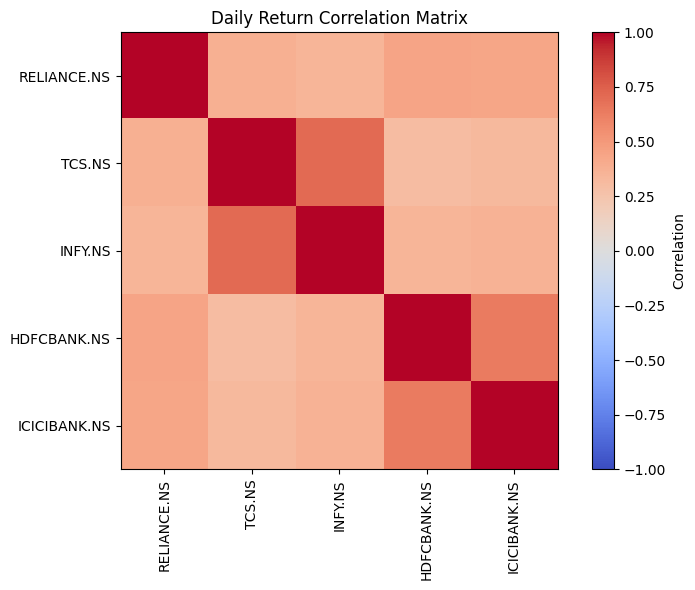

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
ax.set_yticks(range(len(corr_matrix.index)), corr_matrix.index)
ax.set_title("Daily Return Correlation Matrix")
plt.tight_layout()
plt.show()

## Observation

Read the heatmap using the color scale and the numerical correlation matrix. Positive correlations are common among equities exposed to the same broad market, but the magnitude differs across pairs. Lower correlation can reduce portfolio variance because portfolio risk depends on both individual variances and cross-asset covariances.

## Equal-Weight Portfolio

An equal-weight portfolio assigns the same fraction of capital to every stock. With five stocks, each weight is

$$
w_i = \frac{1}{5} = 0.20.
$$

The portfolio's daily return is the weighted sum of the constituent stocks' daily returns. We explicitly select columns in the same order as the weights to prevent ticker-weight mismatches.

In [4]:
weights = np.full(len(stocks), 1 / len(stocks))
portfolio_returns = returns[stocks].dot(weights)
portfolio_returns.head()

,0
Date,
2020-01-02,0.004613
2020-01-03,0.003803
2020-01-06,-0.015783
2020-01-07,0.002705
2020-01-08,0.000955


## Average Daily Portfolio Return

The sample mean of portfolio daily returns is the average daily return over the observation period. It is not an annualized expected return.

In [5]:
portfolio_mean_daily_return = portfolio_returns.mean()
print(f"Average daily portfolio return: {portfolio_mean_daily_return:.6f} ({portfolio_mean_daily_return:.3%})")

Average daily portfolio return: 0.000650 (0.065%)


## Portfolio Volatility

Portfolio volatility is the sample standard deviation of the portfolio's daily returns. It depends on the volatility of each asset and on how the assets co-move. Diversification can reduce risk, but it does not guarantee that the portfolio will be less volatile than every constituent stock.

In [6]:
portfolio_daily_volatility = portfolio_returns.std()
print(f"Portfolio daily volatility: {portfolio_daily_volatility:.6f} ({portfolio_daily_volatility:.2%})")

Portfolio daily volatility: 0.012516 (1.25%)


## Individual Stock Volatility vs Portfolio Volatility

An individual stock's volatility measures the dispersion of that stock's returns. Portfolio volatility measures the dispersion of the combined portfolio returns.

Because assets do not usually move in perfect lockstep, combining them can reduce volatility relative to some or all individual holdings. The comparison below tests this using the actual sample data.

## Individual Stocks vs Portfolio

In [7]:
comparison = pd.DataFrame({
    "Average Daily Return": returns[stocks].mean(),
    "Daily Volatility": returns[stocks].std()
})
comparison.loc["Equal Weight Portfolio"] = [
    portfolio_mean_daily_return,
    portfolio_daily_volatility
]
comparison

,Average Daily Return,Daily Volatility
Ticker,,
RELIANCE.NS,0.000726,0.017810
TCS.NS,0.000464,0.014970
INFY.NS,0.000779,0.017263
HDFCBANK.NS,0.000463,0.016173
ICICIBANK.NS,0.000816,0.018717
Equal Weight Portfolio,0.000650,0.012516


## Portfolio Growth

We compound the portfolio's daily returns to show how ₹1 invested at the beginning of the return sample would have evolved, assuming the portfolio weights are maintained daily. This is a simplified daily-rebalanced portfolio path, not a full trading backtest.

In [8]:
portfolio_growth = (1 + portfolio_returns).cumprod()
portfolio_growth.head()

,0
Date,
2020-01-02,1.004613
2020-01-03,1.008434
2020-01-06,0.992518
2020-01-07,0.995203
2020-01-08,0.996153


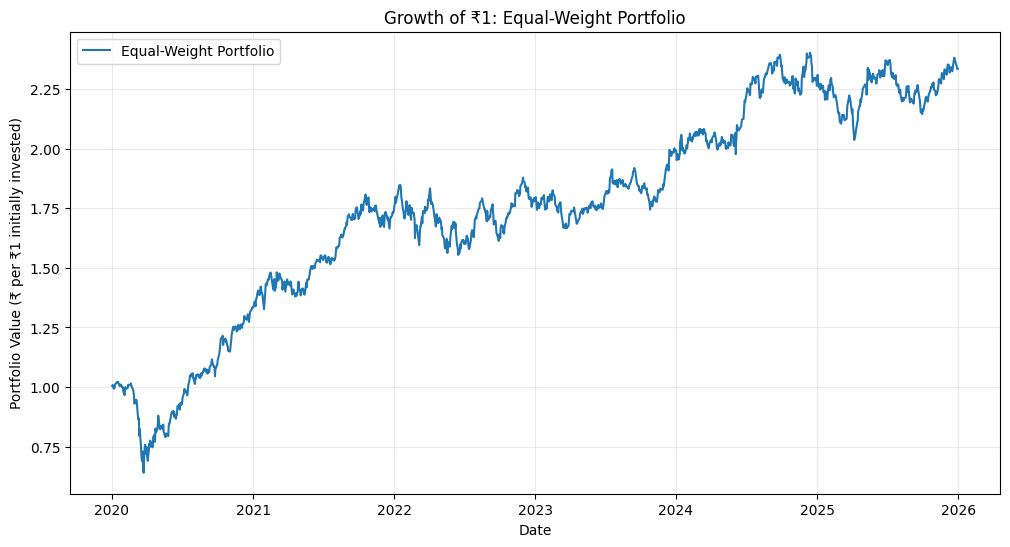

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(portfolio_growth.index, portfolio_growth, label="Equal-Weight Portfolio")
plt.title("Growth of ₹1: Equal-Weight Portfolio")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (₹ per ₹1 initially invested)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

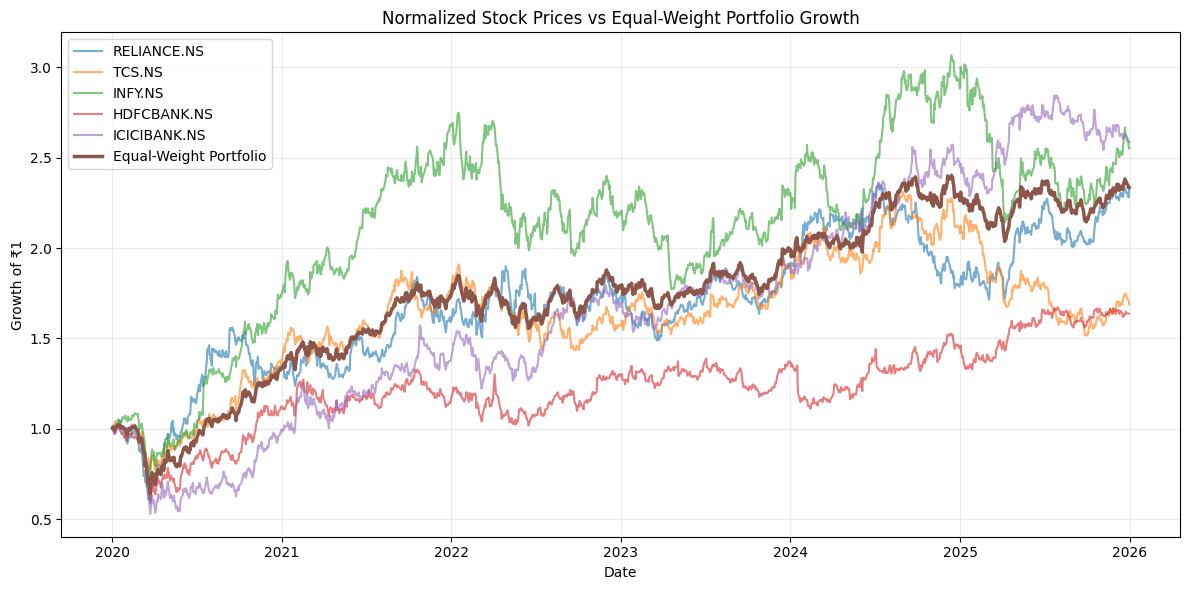

In [10]:
first_valid_prices = close_prices[stocks].apply(lambda column: column.dropna().iloc[0])
normalized_prices = close_prices[stocks].div(first_valid_prices, axis="columns")

plt.figure(figsize=(12, 6))
for ticker in stocks:
    plt.plot(normalized_prices.index, normalized_prices[ticker], alpha=0.6, label=ticker)

plt.plot(portfolio_growth.index, portfolio_growth, linewidth=2.5, label="Equal-Weight Portfolio")
plt.title("Normalized Stock Prices vs Equal-Weight Portfolio Growth")
plt.xlabel("Date")
plt.ylabel("Growth of ₹1")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Conclusions

- Correlation describes how pairs of assets move together and helps explain diversification.
- An equal-weight portfolio provides a transparent baseline allocation.
- Portfolio return is the weighted sum of constituent returns, while portfolio volatility also depends on covariance.
- Diversification can reduce risk, but its benefit depends on the assets and the sample period.
- This notebook provides the baseline portfolio that will be modeled mathematically in the Modern Portfolio Theory notebook.

All results are historical and exclude transaction costs, taxes, and implementation frictions.